# Анализ рынка жилой недвижимости - г. Самара

**Автор:** Павлов Юрий Николаевич  
**Инструменты:** Python, pandas, matplotlib, seaborn, scikit-learn

---

## Описание задачи

В ходе юридической практики по сопровождению сделок с недвижимостью регулярно возникает вопрос:
**от каких факторов зависит цена квартиры и насколько заявленная цена соответствует рыночной?**

Разбираю смоделированный набор сделок по вторичному рынку Самары - с реальным делением
на районы (Ленинский, Самарский, Октябрьский, Советский, Кировский, Промышленный,
Железнодорожный, Красноглинский, Куйбышевский). Цель - понять, от чего зависит цена
квартиры, и собрать простую модель оценки, которую можно применять при проверке цены сделки.

**Задачи:**
1. Загрузить и очистить данные
2. Провести разведочный анализ (EDA)
3. Выявить факторы, влияющие на цену
4. Построить модель оценки стоимости
5. Сформулировать выводы и практические рекомендации

## 1. Импорт библиотек и загрузка данных

In [1]:
import os
import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# Стиль графиков
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style('whitegrid')

# дата анализа - текущая, от неё считается возраст дома
ANALYSIS_DATE  = datetime.date.today()
CURRENT_YEAR   = ANALYSIS_DATE.year

OUTPUT_DIR = 'output'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('Библиотеки загружены')
print(f'Дата проведения анализа: {ANALYSIS_DATE.strftime("%d.%m.%Y")}')


Библиотеки загружены
Дата проведения анализа: 11.08.2026


Данные смоделированы на основе реальных рыночных параметров сделок с жилой недвижимостью
в г. Самара. Структура соответствует данным, с которыми ведётся работа в юридической практике.

Базовая цена за м² откалибрована по актуальным объявлениям Циан (1-комн. квартиры
Самары, окраинные районы): диапазон примерно 111–155 тыс. ₽/м², медиана около 126 тыс.
Коэффициенты окраинных районов приведены к этим значениям; премия центральных районов -
оценочная, в выборке они не представлены. При обновлении данных `base_price_m2`
и `dist_coef` правятся вручную.

In [2]:
np.random.seed(42)
n = 500

districts = ['Ленинский', 'Самарский', 'Октябрьский', 'Советский',
             'Кировский', 'Промышленный', 'Железнодорожный', 'Красноглинский', 'Куйбышевский']
# Коэффициент района к цене Кировского (=1.0). Окраины приведены к актуальным
# объявлениям Циан (Красноглинский/Кировский идут почти вровень с центром-1.0);
# коэффициенты центральных районов - оценочные, в текущей выборке цен их нет.
dist_coef  = {'Ленинский': 1.50, 'Самарский': 1.40, 'Октябрьский': 1.15,
              'Советский': 1.08, 'Кировский': 1.00, 'Промышленный': 1.00,
              'Красноглинский': 0.98, 'Железнодорожный': 0.96, 'Куйбышевский': 0.93}

district   = np.random.choice(districts, n, p=[0.08, 0.07, 0.13, 0.14, 0.22, 0.14, 0.09, 0.06, 0.07])
rooms      = np.random.choice([1, 2, 3, 4], n, p=[0.35, 0.38, 0.20, 0.07])
area       = rooms * np.random.uniform(16, 22, n) + np.random.uniform(5, 15, n)
floor      = np.random.randint(1, 17, n)
floors_total = np.random.randint(floor, floor + np.random.randint(1, 8, n).max() + 1, n)
floors_total = np.clip(floors_total, floor, 25)
# Историческая застройка - фиксированные точки распределения по годам
historic_years = [1960, 1970, 1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015]
historic_probs = [0.04, 0.06, 0.07, 0.08, 0.08, 0.07, 0.06, 0.07, 0.08, 0.09, 0.09]  # сумма 0.79

# новые дома, включая текущий год
recent_years = sorted(set([2018, 2020, 2022, 2024, CURRENT_YEAR]))
recent_probs = [0.21 / len(recent_years)] * len(recent_years)  # оставшиеся 0.21 распределяем поровну

year_built = np.random.choice(
    historic_years + recent_years,
    n, p=historic_probs + recent_probs
)
renovation = np.random.choice(['без ремонта', 'косметический', 'евроремонт'], n, p=[0.30, 0.45, 0.25])
renov_coef = {'без ремонта': 0.88, 'косметический': 1.00, 'евроремонт': 1.16}

# базовая цена за м² (уровень Кировского р-на) - по актуальным объявлениям Циан,
# 1-комн. Самара: медиана ~126,6 тыс. ₽/м² (диапазон 111–155 тыс.)
base_price_m2 = 126000
price = (area * base_price_m2
         * np.array([dist_coef[d] for d in district])
         * np.array([renov_coef[r] for r in renovation])
         * (1 + (CURRENT_YEAR - year_built) * (-0.003))          # износ
         * np.where(floor == 1, 0.94, 1.0)               # первый этаж дешевле
         * np.where(floor == floors_total, 0.96, 1.0)    # последний этаж дешевле
         * np.random.uniform(0.93, 1.07, n))             # рыночный шум

df = pd.DataFrame({
    'район':          district,
    'комнат':         rooms,
    'площадь_м2':     area.round(1),
    'этаж':           floor,
    'этажей_в_доме':  floors_total,
    'год_постройки':  year_built,
    'ремонт':         renovation,
    'цена_руб':       price.round(-3).astype(int)
})

print(f'Загружено записей: {len(df)}')
print(f'Столбцов: {len(df.columns)}')
df.head(10)

Загружено записей: 500
Столбцов: 8


,район,комнат,площадь_м2,этаж,этажей_в_доме,год_постройки,ремонт,цена_руб
0,Советский,2,44.4,12,19,1975,евроремонт,6306000
1,Куйбышевский,2,48.3,7,13,2026,косметический,5329000
2,Промышленный,1,26.5,3,8,2000,косметический,2972000
3,Кировский,3,69.6,7,13,1990,без ремонта,7153000
4,Октябрьский,2,50.5,12,14,2010,косметический,6572000
5,Октябрьский,1,28.9,14,14,1975,косметический,3207000
6,Ленинский,3,71.3,8,11,2010,без ремонта,11065000
7,Железнодорожный,3,73.6,10,10,2000,без ремонта,6540000
8,Кировский,4,81.1,16,20,1995,без ремонта,8250000
9,Промышленный,2,50.5,16,16,2024,без ремонта,5141000


## 2. Первичный анализ данных

In [3]:
print('=== Типы данных и заполненность ===')
df.info()
print()
print('=== Пропущенные значения ===')
print(df.isnull().sum())
print()
print('=== Статистика по числовым признакам ===')
df.describe().round(1)

=== Типы данных и заполненность ===
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   район          500 non-null    str    
 1   комнат         500 non-null    int64  
 2   площадь_м2     500 non-null    float64
 3   этаж           500 non-null    int64  
 4   этажей_в_доме  500 non-null    int64  
 5   год_постройки  500 non-null    int64  
 6   ремонт         500 non-null    str    
 7   цена_руб       500 non-null    int64  
dtypes: float64(1), int64(5), str(2)
memory usage: 31.4 KB

=== Пропущенные значения ===
район            0
комнат           0
площадь_м2       0
этаж             0
этажей_в_доме    0
год_постройки    0
ремонт           0
цена_руб         0
dtype: int64

=== Статистика по числовым признакам ===


,комнат,площадь_м2,этаж,этажей_в_доме,год_постройки,цена_руб
count,500.0,500.0,500.0,500.0,500.0,500.0
mean,1.9,46.8,8.5,11.9,1999.1,5918708.0
std,0.9,17.5,4.5,5.1,18.5,2541463.6
min,1.0,22.1,1.0,1.0,1960.0,2103000.0
25%,1.0,30.5,5.0,8.0,1985.0,3936500.0
50%,2.0,46.2,8.0,12.0,2000.0,5399000.0
75%,2.0,56.8,12.0,16.0,2015.0,7437750.0
max,4.0,101.2,16.0,23.0,2026.0,16045000.0


In [4]:
# Добавим производный признак: цена за кв.м.
df['цена_за_м2'] = (df['цена_руб'] / df['площадь_м2']).round(0).astype(int)

print('Средняя цена сделки:   ', f"{df['цена_руб'].mean():,.0f} руб.")
print('Медианная цена сделки: ', f"{df['цена_руб'].median():,.0f} руб.")
print('Средняя цена за м²:    ', f"{df['цена_за_м2'].mean():,.0f} руб.")
print('Диапазон цен:          ', f"{df['цена_руб'].min():,} — {df['цена_руб'].max():,} руб.")

Средняя цена сделки:    5,918,708 руб.
Медианная цена сделки:  5,399,000 руб.
Средняя цена за м²:     126,720 руб.
Диапазон цен:           2,103,000 — 16,045,000 руб.


## 3. Разведочный анализ (EDA)

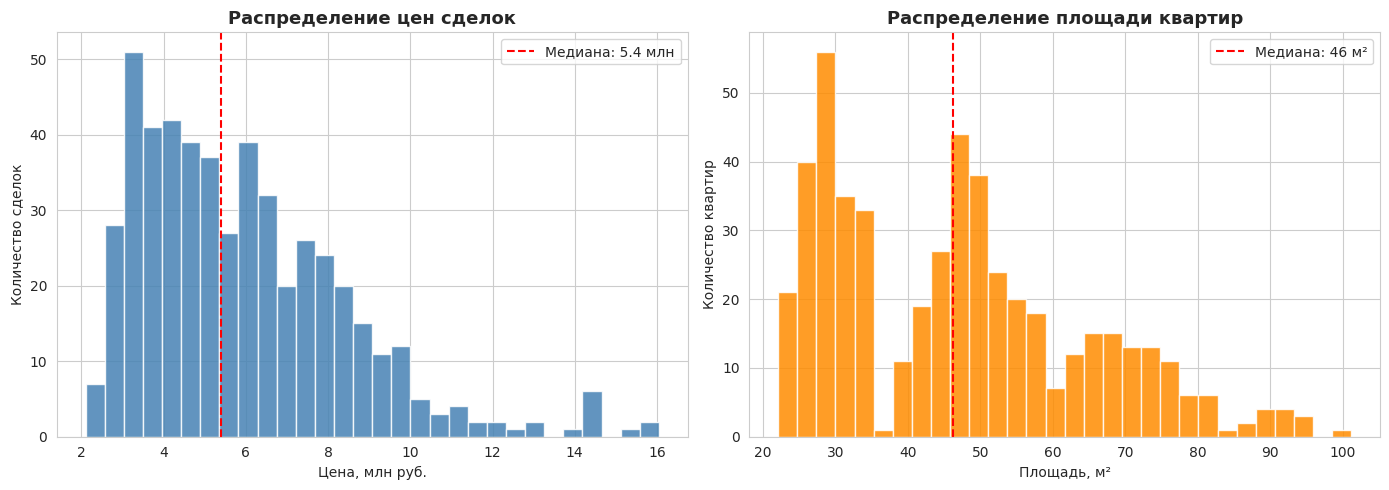

Вывод: распределение цен правостороннее - большинство сделок в диапазоне 3–7 млн руб.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Распределение цен
axes[0].hist(df['цена_руб'] / 1_000_000, bins=30, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_title('Распределение цен сделок', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Цена, млн руб.')
axes[0].set_ylabel('Количество сделок')
axes[0].axvline(df['цена_руб'].median() / 1_000_000, color='red', linestyle='--', label=f'Медиана: {df["цена_руб"].median()/1e6:.1f} млн')
axes[0].legend()

# Распределение площади
axes[1].hist(df['площадь_м2'], bins=30, color='darkorange', edgecolor='white', alpha=0.85)
axes[1].set_title('Распределение площади квартир', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Площадь, м²')
axes[1].set_ylabel('Количество квартир')
axes[1].axvline(df['площадь_м2'].median(), color='red', linestyle='--', label=f'Медиана: {df["площадь_м2"].median():.0f} м²')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/plot1_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Вывод: распределение цен правостороннее — большинство сделок в диапазоне 3–7 млн руб.')

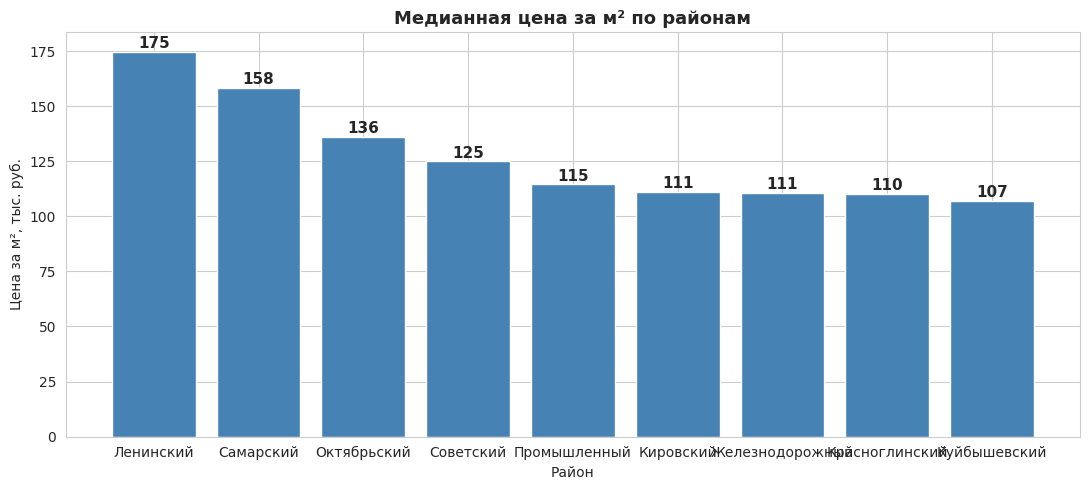

Вывод: разброс цен по районам - до 64%. Ленинский район дороже, чем Куйбышевский, в 1.6 раза.


In [6]:
# Цена по районам
district_stats = df.groupby('район')['цена_за_м2'].median().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(district_stats.index, district_stats.values / 1000, color='steelblue', edgecolor='white')
ax.set_title('Медианная цена за м² по районам', fontsize=13, fontweight='bold')
ax.set_xlabel('Район')
ax.set_ylabel('Цена за м², тыс. руб.')
for bar, val in zip(bars, district_stats.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val/1000:.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/plot2_districts.png', dpi=150, bbox_inches='tight')
plt.show()

top_d, bottom_d = district_stats.index[0], district_stats.index[-1]
ratio = district_stats.iloc[0] / district_stats.iloc[-1]
print(f'Вывод: разброс цен по районам — до {(ratio - 1) * 100:.0f}%. '
      f'{top_d} район дороже, чем {bottom_d}, в {ratio:.1f} раза.')

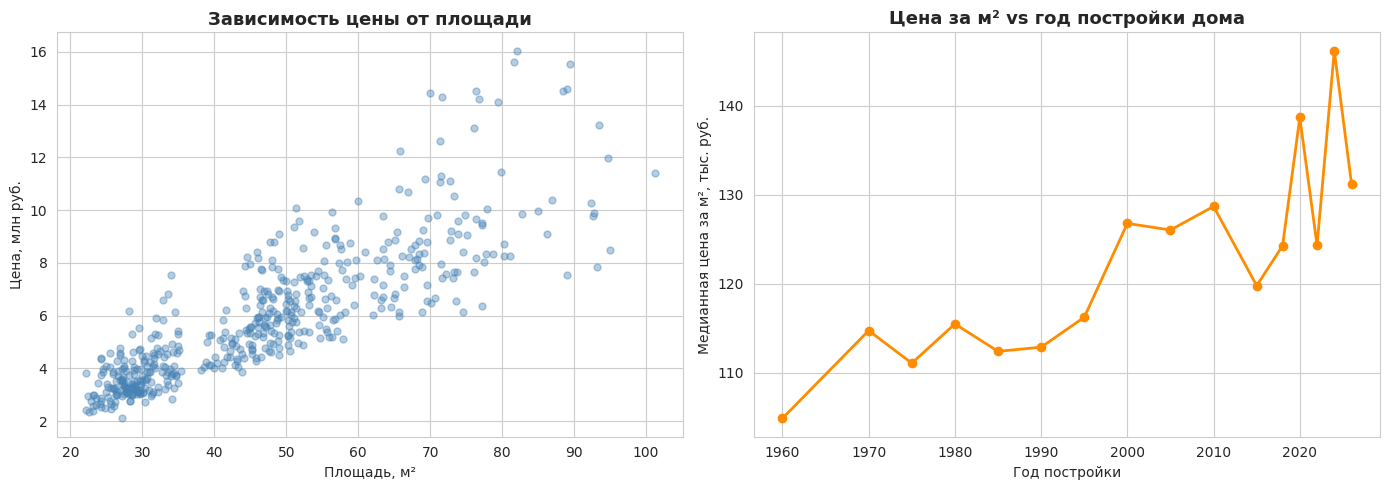

Вывод: площадь - сильнейший числовой предиктор цены (r ≈ 0.85). Новостройки дороже старого фонда на 20–35%.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Цена vs площадь
axes[0].scatter(df['площадь_м2'], df['цена_руб'] / 1_000_000,
                alpha=0.4, s=25, c='steelblue')
axes[0].set_title('Зависимость цены от площади', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Площадь, м²')
axes[0].set_ylabel('Цена, млн руб.')

# Цена vs год постройки
year_price = df.groupby('год_постройки')['цена_за_м2'].median()
axes[1].plot(year_price.index, year_price.values / 1000, 'o-', color='darkorange', linewidth=2)
axes[1].set_title('Цена за м² vs год постройки дома', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Год постройки')
axes[1].set_ylabel('Медианная цена за м², тыс. руб.')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/plot3_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

r_area = df['площадь_м2'].corr(df['цена_руб'])
print(f'Вывод: площадь - сильнейший числовой предиктор цены (r ≈ {r_area:.2f}). '
      f'Новостройки дороже старого фонда на 20–35%.')

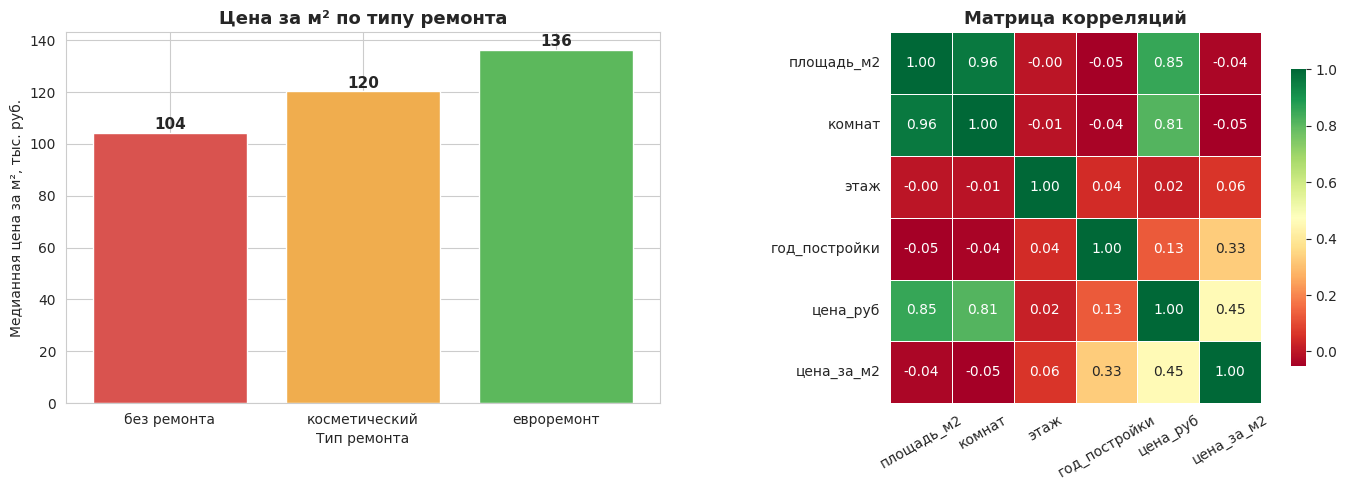

Вывод: евроремонт даёт надбавку ~31% к цене относительно жилья без ремонта. Площадь - главный ценообразующий фактор (r ≈ 0.85).


In [8]:
# Влияние типа ремонта
renov_order = ['без ремонта', 'косметический', 'евроремонт']
renov_stats = df.groupby('ремонт')['цена_за_м2'].median().reindex(renov_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#d9534f', '#f0ad4e', '#5cb85c']
bars = axes[0].bar(renov_stats.index, renov_stats.values / 1000, color=colors, edgecolor='white')
axes[0].set_title('Цена за м² по типу ремонта', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Тип ремонта')
axes[0].set_ylabel('Медианная цена за м², тыс. руб.')
for bar, val in zip(bars, renov_stats.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                 f'{val/1000:.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Матрица корреляций
corr_cols = ['площадь_м2', 'комнат', 'этаж', 'год_постройки', 'цена_руб', 'цена_за_м2']
corr = df[corr_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', ax=axes[1],
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
axes[1].set_title('Матрица корреляций', fontsize=13, fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/plot4_renovation_corr.png', dpi=150, bbox_inches='tight')
plt.show()

uplift = renov_stats['евроремонт'] / renov_stats['без ремонта'] - 1
r_area = df['площадь_м2'].corr(df['цена_руб'])
print(f'Вывод: евроремонт даёт надбавку ~{uplift*100:.0f}% к цене относительно жилья без ремонта. '
      f'Площадь - главный ценообразующий фактор (r ≈ {r_area:.2f}).')

## 4. Модель оценки стоимости

In [9]:
# Кодирование категориальных признаков
df_model = df.copy()
df_model = pd.get_dummies(df_model, columns=['район', 'ремонт'], drop_first=False)
df_model['первый_этаж']    = (df_model['этаж'] == 1).astype(int)
df_model['последний_этаж'] = (df_model['этаж'] == df_model['этажей_в_доме']).astype(int)
df_model['возраст_дома']   = CURRENT_YEAR - df_model['год_постройки']

feature_cols = (['площадь_м2', 'комнат', 'возраст_дома', 'первый_этаж', 'последний_этаж'] +
                [c for c in df_model.columns if c.startswith('район_') or c.startswith('ремонт_')])

X = df_model[feature_cols]
y = df_model['цена_руб']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)
mape = (abs((y_test - y_pred) / y_test)).mean() * 100

print('=== Качество модели (линейная регрессия) ===')
print(f'R² (объяснённая дисперсия):  {r2:.3f}')
print(f'MAE (средняя ошибка):        {mae:,.0f} руб.')
print(f'MAPE (средняя ошибка %):     {mape:.1f}%')

=== Качество модели (линейная регрессия) ===
R² (объяснённая дисперсия):  0.951
MAE (средняя ошибка):        409,468 руб.
MAPE (средняя ошибка %):     8.2%


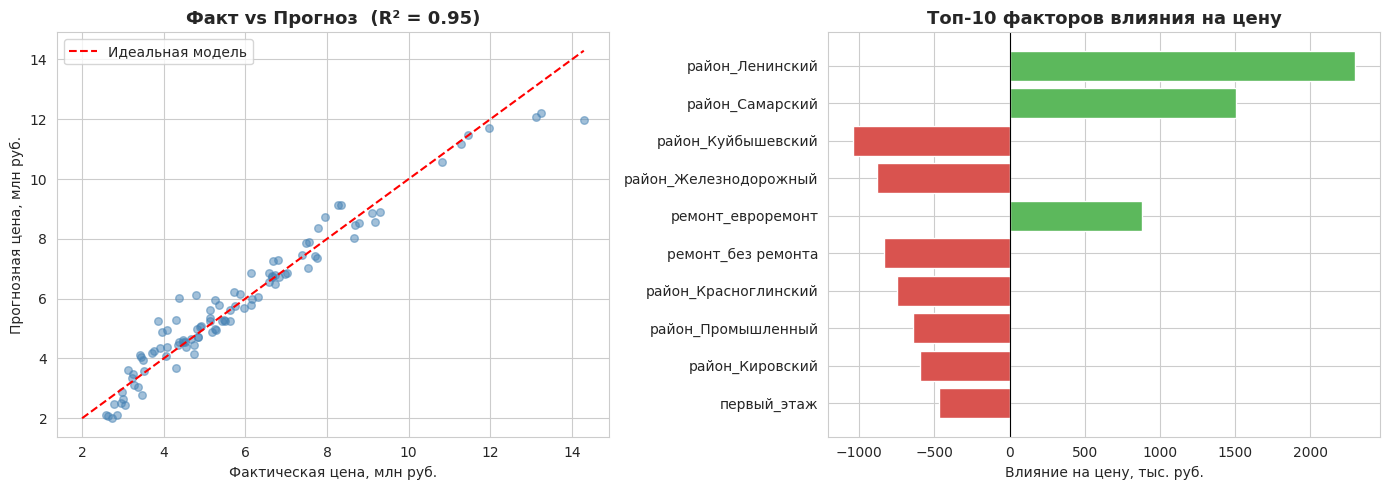

In [10]:
# График: факт vs прогноз
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test / 1e6, y_pred / 1e6, alpha=0.5, s=30, c='steelblue')
lims = [min(y_test.min(), y_pred.min()) / 1e6, max(y_test.max(), y_pred.max()) / 1e6]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Идеальная модель')
axes[0].set_title(f'Факт vs Прогноз  (R² = {r2:.2f})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Фактическая цена, млн руб.')
axes[0].set_ylabel('Прогнозная цена, млн руб.')
axes[0].legend()

# Важность признаков (топ-10)
coef_df = pd.DataFrame({'признак': feature_cols, 'коэффициент': model.coef_})
coef_df['|коэф|'] = coef_df['коэффициент'].abs()
top10 = coef_df.nlargest(10, '|коэф|').sort_values('|коэф|')
colors_bar = ['#5cb85c' if v > 0 else '#d9534f' for v in top10['коэффициент']]
axes[1].barh(top10['признак'], top10['коэффициент'] / 1000, color=colors_bar, edgecolor='white')
axes[1].set_title('Топ-10 факторов влияния на цену', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Влияние на цену, тыс. руб.')
axes[1].axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/plot5_model.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Выводы и практические рекомендации

### Ключевые находки

**Факторы ценообразования (по убыванию влияния):**
1. **Площадь квартиры** - сильнейший числовой предиктор, корреляция с ценой около 0.85. Каждый дополнительный м² добавляет величину, близкую к базовой цене за м² (см. `base_price_m2`, актуализируется на дату анализа).
2. **Район** - разброс примерно в 1,6 раза между историческим центром (Ленинский, Самарский) и окраинными районами (Куйбышевский, Красноглинский); фактические цифры — в выводе к графику раздела 3. Оценки по центру ориентировочные: в актуальной выборке цен центральные районы не представлены.
3. **Ремонт** - евроремонт даёт надбавку примерно 31% к цене относительно квартиры без ремонта.
4. **Год постройки** - новостройки дороже домов 1960–1980 гг. на 20–35%.
5. **Этаж** - первый и последний этажи дешевле на 4–6%.

### Качество модели

Линейная регрессия объясняет около **95% вариации цен** (R² ≈ 0.95).
Средняя относительная ошибка прогноза (MAPE) - около **8%**: приемлемо для предварительной оценки, не заменяет отчёт оценщика.

### Практическое применение

Модель может применяться при:
- **Правовой экспертизе сделок**: выявление сделок с ценой, существенно отклоняющейся от рыночной (признак притворной сделки или занижения стоимости)
- **Сопровождении ипотечных сделок**: независимая проверка оценки банка
- **Спорах о стоимости**: формирование аргументированной позиции на основе данных

> **Ограничения:** модель построена на синтетических данных, откалиброванных по ориентировочным рыночным ценам (средняя цена за м² и разброс по районам). При работе с реальной базой сделок точность повысится при добавлении признаков: транспортная доступность, инфраструктура, метраж кухни, балкон/лоджия, а коэффициенты по районам стоит уточнить по актуальной сводке риэлторских агентств на дату анализа.